# BÀI TẬP LỚN HỌC PHẦN: NHẬP MÔN HỌC MÁY
**Đề tài 8: Dự đoán sinh viên có nguy cơ bỏ học**

- **Giảng viên hướng dẫn:** ThS. Lê Thị Thùy Trang
- **Trường:** Đại học Đại Nam
- **Thành viên thực hiện:** 
  - Phùng Quang Trung - 1871020590 
  - Đỗ Bảo Nguyên - 1871020433  
  - Đào Ngọc Nam - 1871020404 
  - Phạm Văn Tuấn Vũ - 1871020672 

**Mục tiêu bài toán:** Xây dựng một quy trình học máy hoàn chỉnh (End-to-End) để dự đoán sinh viên có khả năng bỏ học. Dự án bao gồm các bước: Khám phá dữ liệu (EDA), tiền xử lý, trích xuất đặc trưng, huấn luyện các thuật toán phân loại và phân tích lỗi. Việc phát hiện sớm sẽ giúp nhà trường có biện pháp can thiệp và hỗ trợ sinh viên kịp thời.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

try:
    import threadpoolctl
    if hasattr(threadpoolctl, "MKLController"):
        threadpoolctl.MKLController.get_num_threads = lambda self: 1
        threadpoolctl.MKLController.set_num_threads = lambda self, n: None
except ImportError:
    pass

import sys
import importlib
import warnings
import numpy as np
from pathlib import Path

warnings.filterwarnings('ignore')

# Tự động tìm thư mục gốc dự án (tìm cả thư mục hiện tại, thư mục cha và thư mục con DUDOANSINHVIEN)
candidates = [
    Path.cwd(),
    Path.cwd() / "DUDOANSINHVIEN",
    *Path.cwd().parents,
]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "src" / "__init__.py").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Không tìm thấy thư mục chứa src/__init__.py từ vị trí hiện tại: {Path.cwd()}"
    )

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src.utils import (
    DATA_PATH, FIGURES_DIR, ERROR_CSV_PATH, TUNING_CSV_PATH, set_seed, ensure_directories
)
import src.preprocessing as preprocessing
importlib.reload(preprocessing)
from src.preprocessing import (
    load_and_clean_data, print_eda_overview, split_train_test,
    build_preprocessor_flow_a, build_preprocessor_flow_b
)
import src.train_evaluate as train_evaluate
importlib.reload(train_evaluate)
run_experiment_pipeline = train_evaluate.run_experiment_pipeline

set_seed(42)
ensure_directories()
print(f"[OK] Đã kết nối thư mục dự án: {PROJECT_ROOT}")

[OK] Đã kết nối thư mục dự án: d:\test


## 1. Khám phá và Phân tích dữ liệu (EDA)
Trước khi đưa vào mô hình, dữ liệu cần được phân tích để hiểu rõ cấu trúc và các vấn đề tiềm ẩn.
- **Mục tiêu:** Kiểm tra kích thước tập dữ liệu, các giá trị thiếu (missing values), giá trị trùng lặp và kiểu dữ liệu của từng cột.
- **Phân phối nhãn:** Đánh giá mức độ mất cân bằng giữa hai lớp `Graduate` (Tốt nghiệp) và `Dropout` (Bỏ học).
- **Ngoại lệ (Outliers):** Xem xét các đặc trưng số học (điểm số, độ tuổi, các chỉ số kinh tế vĩ mô) để có chiến lược chuẩn hóa phù hợp ở bước tiền xử lý.

In [2]:
# Đọc dữ liệu từ thư mục raw và hiển thị báo cáo tổng quan
df = load_and_clean_data(DATA_PATH)
print_eda_overview(df)

# Xem thử 5 dòng đầu tiên của tập dữ liệu
display(df.head(5))

Kích thước dữ liệu (sau khi lọc Enrolled): 3630 dòng x 37 cột
Tổng số giá trị thiếu (Missing values): 0
Phân phối lớp: Graduate (0) = 2209 | Dropout (1) = 1421


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Dropout
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,1
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,0
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,1
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,0
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,0


## 2. Tiền xử lý dữ liệu và Kỹ thuật đặc trưng (Feature Engineering)
Dữ liệu được chia thành tập huấn luyện (Train) và tập kiểm thử (Test) ngay từ đầu để **ngăn chặn rò rỉ dữ liệu (Data Leakage)**. Tiếp theo, nhóm thiết kế 2 luồng tiền xử lý để so sánh:

- **Luồng A (Baseline - Cơ bản):** Giữ nguyên các thuộc tính gốc (chỉ bỏ cột định danh). Điền khuyết cơ bản, mã hóa One-Hot cho biến phân loại và chuẩn hóa `StandardScaler` cho biến số.
- **Luồng B (Advanced - Cải tiến):** Dựa trên tri thức miền, nhóm tạo thêm các biến phái sinh có ý nghĩa (ví dụ: Tỷ lệ qua môn, Rủi ro tài chính). Sử dụng `RobustScaler` để xử lý các cột có nhiều nhiễu/ngoại lệ và gộp nhóm các thuộc tính thiểu số.

In [3]:
# Chia tập dữ liệu 80/20 (Sử dụng Stratify để giữ nguyên tỷ lệ lớp Dropout/Graduate)
X_train, X_test, y_train, y_test = split_train_test(df, test_size=0.20)

# Khởi tạo Pipeline cho 2 luồng
preproc_a = build_preprocessor_flow_a(X_train)
preproc_b = build_preprocessor_flow_b(X_train)

# Fit trên tập Train và Transform
XA_train = preproc_a.fit_transform(X_train)
XB_train = preproc_b.fit_transform(X_train)

print(f'Train: {X_train.shape[0]} mẫu | Test: {X_test.shape[0]} mẫu')
print(f'Số chiều Luồng A: {XA_train.shape[1]} đặc trưng')
print(f'Số chiều Luồng B: {XB_train.shape[1]} đặc trưng')

Train: 2904 mẫu | Test: 726 mẫu
Số chiều Luồng A: 36 đặc trưng
Số chiều Luồng B: 40 đặc trưng


## 3. Huấn luyện mô hình và Đánh giá đa chỉ số
Nhóm tiến hành huấn luyện các thuật toán cơ bản gồm **K-Nearest Neighbors (K-NN), Naive Bayes, và Decision Tree** trên cả hai Luồng A và B.
- **Tinh chỉnh tham số:** Sử dụng `GridSearchCV` kết hợp kiểm chứng chéo (Cross-validation) để tìm bộ tham số tối ưu (ví dụ: `k` trong K-NN, `max_depth` trong Decision Tree).
- **Tiêu chí đánh giá:** Bài toán dự đoán sinh viên bỏ học cần hạn chế tối đa việc bỏ lọt (dự đoán nhầm sinh viên sẽ bỏ học thành an toàn). Do đó, nhóm ưu tiên đánh giá dựa trên **Recall (Độ phủ)** và **F1-score**, thay vì chỉ nhìn vào Accuracy.

In [4]:
from src.utils import RESULTS_CSV_PATH

# Nếu đã chạy run_pipeline.py trước đó thì đọc trực tiếp kết quả để tránh xung đột MKL trên Jupyter Windows
if RESULTS_CSV_PATH.exists() and TUNING_CSV_PATH.exists() and ERROR_CSV_PATH.exists():
    results_df = pd.read_csv(RESULTS_CSV_PATH)
    tuning_df = pd.read_csv(TUNING_CSV_PATH)
    error_df = pd.read_csv(ERROR_CSV_PATH)
else:
    results_df = run_experiment_pipeline()
    tuning_df = pd.read_csv(TUNING_CSV_PATH)
    error_df = pd.read_csv(ERROR_CSV_PATH)

print("=== BẢNG ĐÁNH GIÁ ĐA CHỈ SỐ TRÊN TẬP KIỂM THỬ ===")
display(results_df)

=== BẢNG ĐÁNH GIÁ ĐA CHỈ SỐ TRÊN TẬP KIỂM THỬ ===


,Model,Flow,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,RandomForest,Flow_B,0.9270,0.9170,0.8944,0.9055,0.9714
1,RandomForest,Flow_A,0.9270,0.9200,0.8908,0.9052,0.9714
2,DecisionTree,Flow_B,0.9132,0.8989,0.8768,0.8877,0.9559
3,DecisionTree,Flow_A,0.8981,0.9008,0.8310,0.8645,0.9281
4,NaiveBayes,Flow_B,0.8815,0.8640,0.8275,0.8453,0.9251
5,KNN,Flow_A,0.8733,0.9174,0.7430,0.8210,0.9076
6,KNN,Flow_B,0.8623,0.9259,0.7042,0.8000,0.9289
7,NaiveBayes,Flow_A,0.8457,0.8162,0.7817,0.7986,0.9103


## 4. Trực quan hóa kết quả thực nghiệm
Các biểu đồ dưới đây giúp minh họa rõ hơn về đặc điểm dữ liệu và hiệu năng của mô hình:
- **Biểu đồ EDA:** Trực quan hóa phân phối nhãn, tương quan tài chính và boxplot điểm số.
- **Biểu đồ Model:** Đường cong ROC-AUC đánh giá khả năng phân loại, Ma trận nhầm lẫn (Confusion Matrix) để xem chi tiết dự đoán đúng/sai, và Biểu đồ mức độ quan trọng của đặc trưng (Feature Importance).

=== BẢNG KẾT QUẢ KHẢO SÁT SIÊU THAM SỐ (TUNING) ===


,Experiment,Best_Params,CV_Best_F1,Test_F1
0,KNN-Flow_A,"{'clf__n_neighbors': 5, 'clf__weights': 'unifo...",0.7697,0.8210
1,NaiveBayes-Flow_A,{'clf__var_smoothing': 1e-09},0.7786,0.7986
2,DecisionTree-Flow_A,"{'clf__max_depth': 5, 'clf__min_samples_split'...",0.8308,0.8645
3,RandomForest-Flow_A,"{'clf__max_depth': None, 'clf__n_estimators': ...",0.8668,0.9052
4,KNN-Flow_B,"{'clf__n_neighbors': 11, 'clf__weights': 'dist...",0.7828,0.8000
5,NaiveBayes-Flow_B,{'clf__var_smoothing': 1e-09},0.8044,0.8453
6,DecisionTree-Flow_B,"{'clf__max_depth': 5, 'clf__min_samples_split'...",0.8384,0.8877
7,RandomForest-Flow_B,"{'clf__max_depth': 10, 'clf__n_estimators': 200}",0.8709,0.9055



=== CÁC BIỂU ĐỒ TRỰC QUAN (EDA & ĐÁNH GIÁ MÔ HÌNH) ===


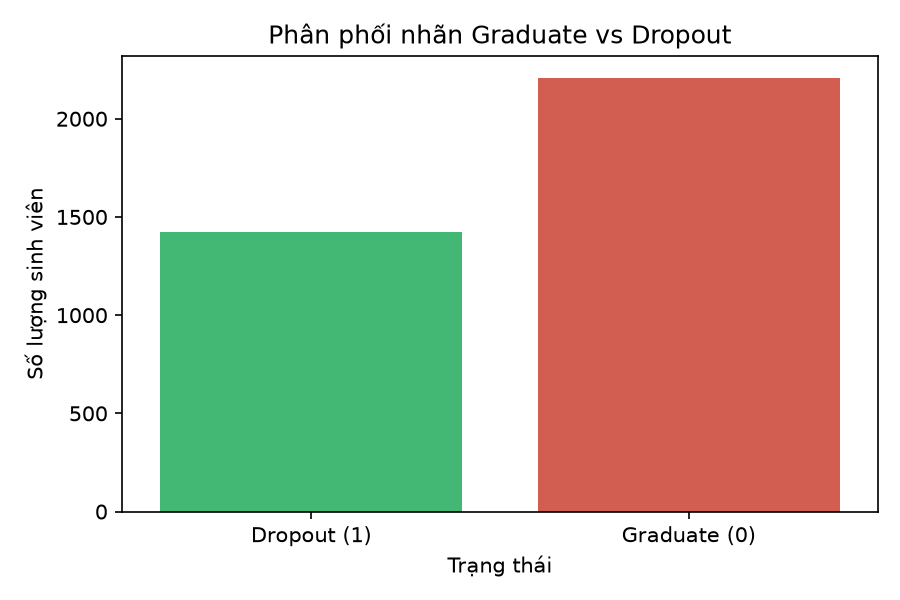

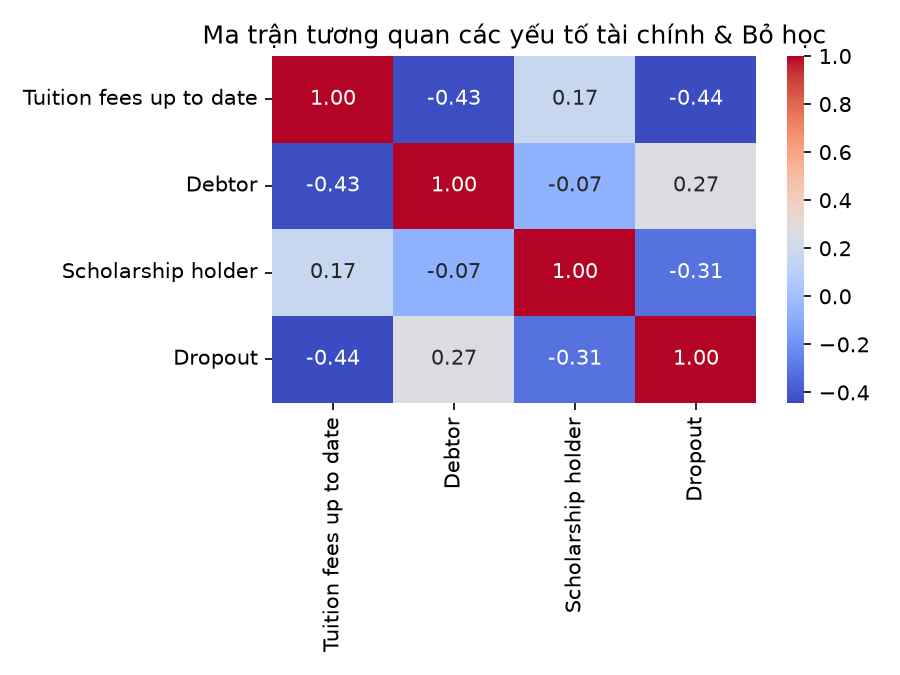

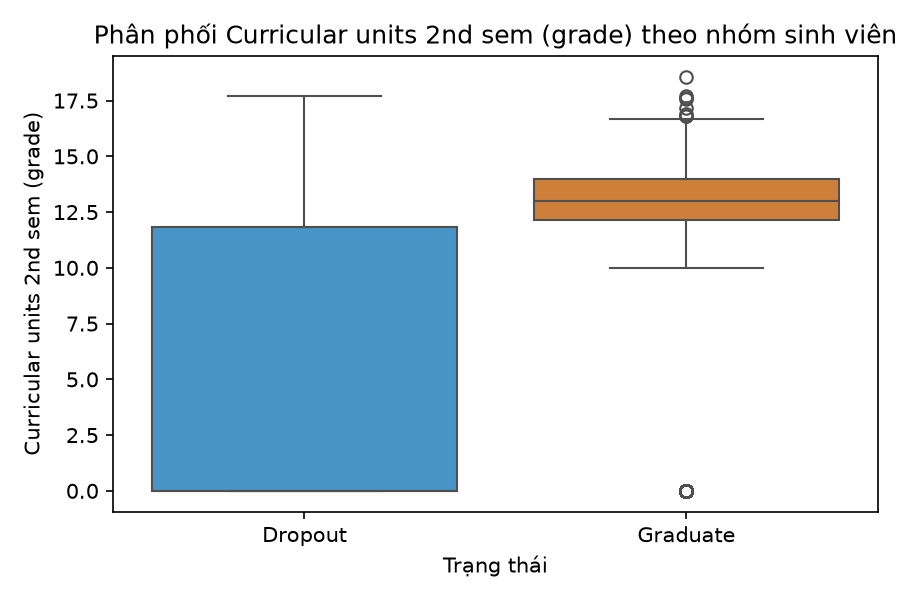

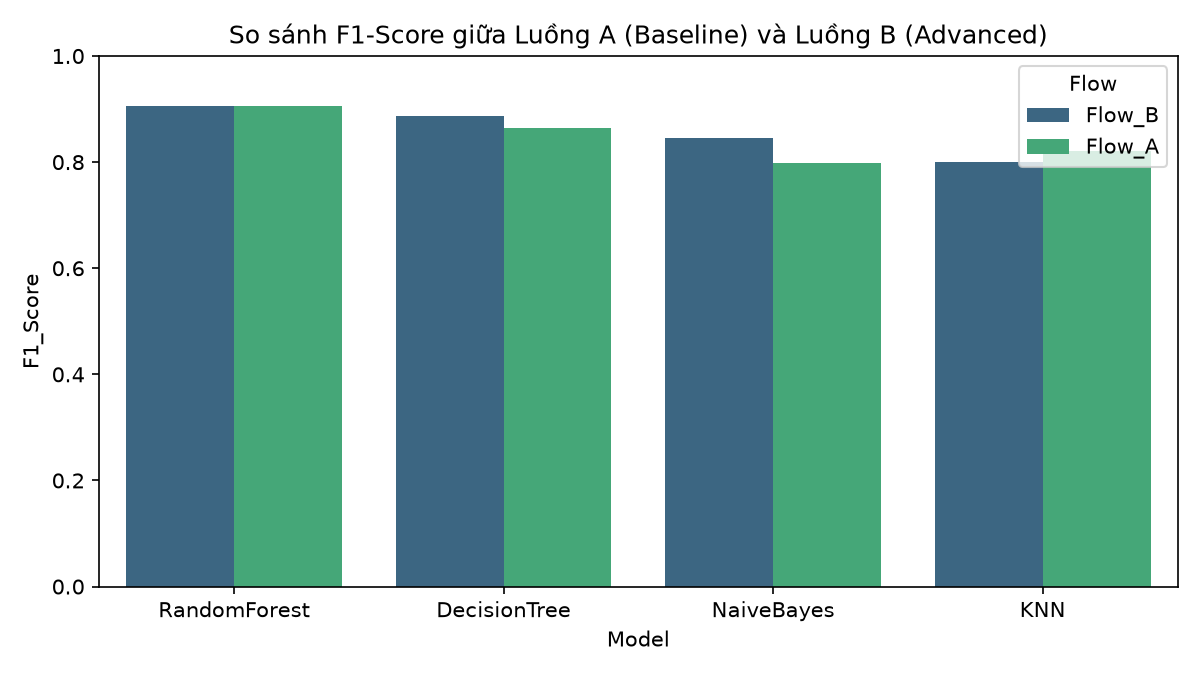

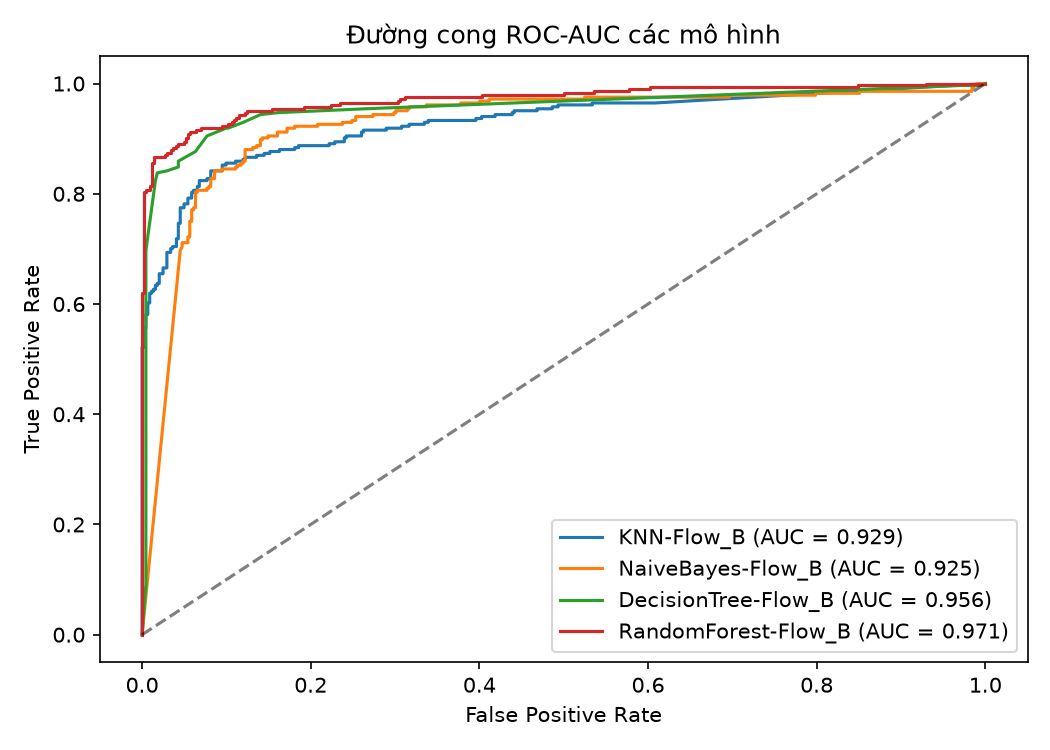

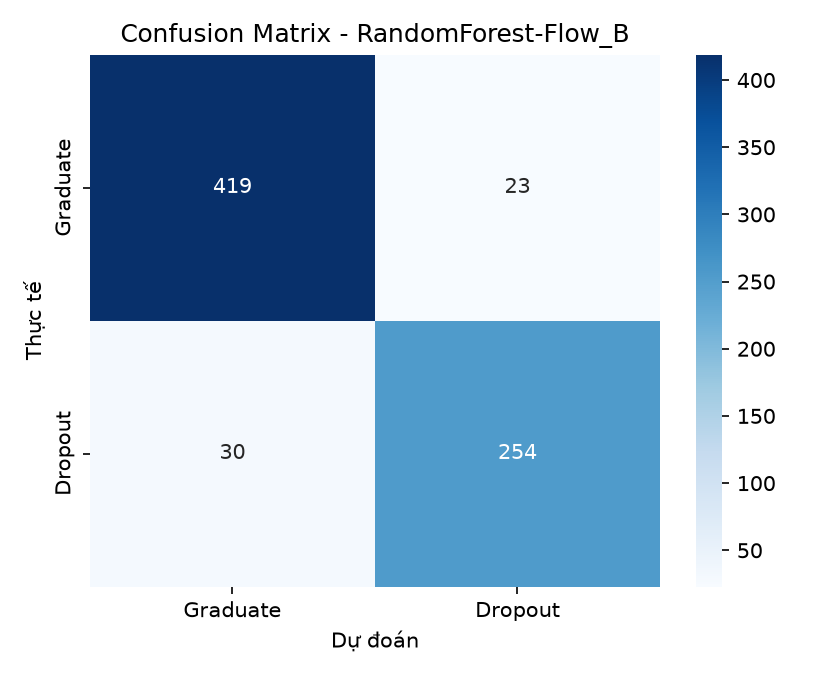

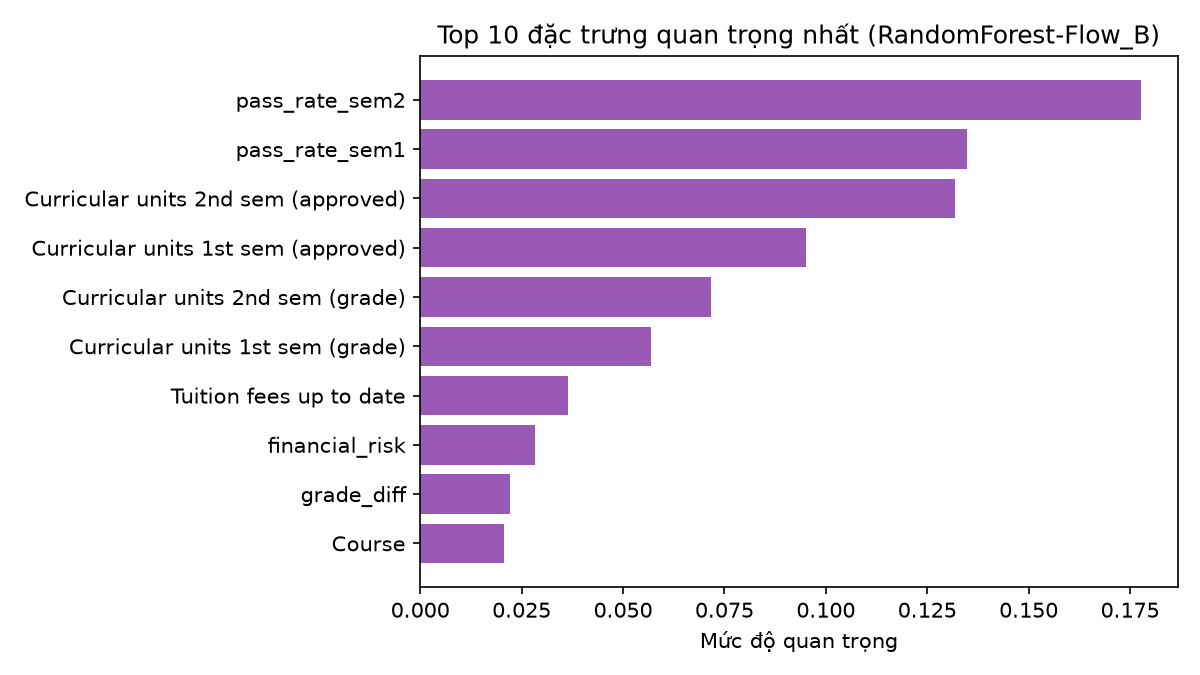

In [5]:
if not tuning_df.empty:
    print("=== BẢNG KẾT QUẢ KHẢO SÁT SIÊU THAM SỐ (TUNING) ===")
    display(tuning_df) 

print("\n=== CÁC BIỂU ĐỒ TRỰC QUAN (EDA & ĐÁNH GIÁ MÔ HÌNH) ===")
image_list = [
    'hinh1_phan_phoi_nhan.png',
    'hinh2_tai_chinh_tuong_quan.png',
    'hinh3_boxplot_hoc_tap.png',
    'hinh4_so_sanh_luong_A_B.png',
    'hinh5_roc_auc_curve.png',
    'hinh6_confusion_matrix.png',
    'hinh7_feature_importance.png'
]

for img_name in image_list:
    img_path = FIGURES_DIR / img_name
    if img_path.exists():
        display(Image(filename=str(img_path), width=760))
    else:
        print(f"[!] Không tìm thấy ảnh: {img_name}")

## 5. Phân tích lỗi (Error Analysis) và Phân tầng rủi ro
Đánh giá độ chính xác chung là chưa đủ, bước này tập trung mổ xẻ các dự đoán sai của mô hình tốt nhất trên tập kiểm thử:
- **Phân tầng rủi ro:** Phân loại sinh viên thành 3 mức rủi ro dựa trên xác suất dự đoán: Thấp (< 40%), Trung bình (40% - 70%), Cao (>= 70%). Giúp nhà trường có chiến lược tiếp cận và phân bổ nguồn lực phù hợp.
- **Âm tính giả (False Negative - FN):** Sinh viên thực tế bỏ học nhưng hệ thống báo an toàn. Đây là sai lầm nguy hiểm nhất vì nhà trường sẽ bỏ lỡ cơ hội can thiệp.
- **Dương tính giả (False Positive - FP):** Sinh viên đi học bình thường nhưng bị hệ thống cảnh báo nhầm thành có nguy cơ bỏ học. Điều này có thể gây lãng phí thời gian và nguồn lực hỗ trợ của trường.

In [6]:
# Xác định tên cột phân loại lỗi từ file kết quả
err_col = 'Error_Type' if 'Error_Type' in error_df.columns else 'Prediction_Status'

# ==============================================================================
# 1. PHÂN TẦNG RỦI RO THÀNH 3 MỨC (Thấp, Trung bình, Cao)
# ==============================================================================
# Phân chia 3 mức rủi ro dựa trên cột xác suất dự đoán (Dropout_Probability)
if 'Dropout_Probability' in error_df.columns:
    conditions = [
        (error_df['Dropout_Probability'] < 0.40),
        (error_df['Dropout_Probability'] >= 0.40) & (error_df['Dropout_Probability'] < 0.70),
        (error_df['Dropout_Probability'] >= 0.70)
    ]
    choices = ['Thấp (< 40%)', 'Trung bình (40% - 70%)', 'Cao (>= 70%)']
    error_df['Custom_Risk_Tier'] = np.select(conditions, choices, default='Khác')
    tier_col_name = 'Custom_Risk_Tier'
else:
    tier_col_name = 'Risk_Tier'

print('=== THỐNG KÊ PHÂN TẦNG RỦI RO TRÊN TẬP KIỂM THỬ ===')
tier_table = error_df.groupby(tier_col_name)['Actual_Dropout'].agg(
    So_luong_SV='count', So_bo_hoc_that='sum', Ty_le_bo_hoc_that='mean'
).reset_index()
# Chuyển đổi tỷ lệ thành phần trăm
tier_table['Ty_le_bo_hoc_that'] = (tier_table['Ty_le_bo_hoc_that'] * 100).round(2).astype(str) + '%'
display(tier_table)

# Lọc các cột đặc trưng quan trọng để đối chiếu nguyên nhân các ca lỗi
cols_inspect = [
    c for c in ['Test_Student_Index', 'Actual_Dropout', 'Predicted_Dropout', 
                'Dropout_Probability', tier_col_name, 'Curricular units 1st sem (approved)', 
                'Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Debtor'] 
    if c in error_df.columns
]

# ==============================================================================
# 2. PHÂN TÍCH ÂM TÍNH GIẢ (FALSE NEGATIVE - FN)
# ==============================================================================
print("\n=== TOP 5 CA ÂM TÍNH GIẢ (FALSE NEGATIVE - FN) ĐIỂN HÌNH ===")
print("(*) Sinh viên thực tế bỏ học nhưng mô hình dự đoán An toàn")
fn_cases = error_df[error_df[err_col].str.contains('FN|False Negative', na=False, case=False)]
display(fn_cases[cols_inspect].head(5))

# ==============================================================================
# 3. PHÂN TÍCH DƯƠNG TÍNH GIẢ (FALSE POSITIVE - FP)
# ==============================================================================
print("\n=== TOP 5 CA DƯƠNG TÍNH GIẢ (FALSE POSITIVE - FP) ĐIỂN HÌNH ===")
print("(*) Sinh viên thực tế đi học bình thường nhưng mô hình Cảnh báo nhầm")
fp_cases = error_df[error_df[err_col].str.contains('FP|False Positive', na=False, case=False)]
display(fp_cases[cols_inspect].head(5))

=== THỐNG KÊ PHÂN TẦNG RỦI RO TRÊN TẬP KIỂM THỬ ===


,Custom_Risk_Tier,So_luong_SV,So_bo_hoc_that,Ty_le_bo_hoc_that
0,Cao (>= 70%),241,236,97.93%
1,Thấp (< 40%),425,23,5.41%
2,Trung bình (40% - 70%),60,25,41.67%



=== TOP 5 CA ÂM TÍNH GIẢ (FALSE NEGATIVE - FN) ĐIỂN HÌNH ===
(*) Sinh viên thực tế bỏ học nhưng mô hình dự đoán An toàn


,Test_Student_Index,Actual_Dropout,Predicted_Dropout,Dropout_Probability,Custom_Risk_Tier,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Tuition fees up to date,Debtor
2,2,1,0,0.3648,Thấp (< 40%),0,0,1,0
33,33,1,0,0.0915,Thấp (< 40%),17,16,1,0
63,63,1,0,0.4980,Trung bình (40% - 70%),6,4,1,0
74,74,1,0,0.1121,Thấp (< 40%),0,0,1,0
81,81,1,0,0.1166,Thấp (< 40%),6,5,1,0



=== TOP 5 CA DƯƠNG TÍNH GIẢ (FALSE POSITIVE - FP) ĐIỂN HÌNH ===
(*) Sinh viên thực tế đi học bình thường nhưng mô hình Cảnh báo nhầm


,Test_Student_Index,Actual_Dropout,Predicted_Dropout,Dropout_Probability,Custom_Risk_Tier,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Tuition fees up to date,Debtor
4,4,0,1,0.5950,Trung bình (40% - 70%),0,0,1,0
30,30,0,1,0.6347,Trung bình (40% - 70%),4,3,1,0
84,84,0,1,0.5647,Trung bình (40% - 70%),4,3,1,0
86,86,0,1,0.6166,Trung bình (40% - 70%),4,6,0,0
112,112,0,1,0.6064,Trung bình (40% - 70%),0,0,1,0
